In [1]:
%load_ext autoreload
%autoreload 2
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

import sys
import numpy as np
# import matplotlib.pyplot as plt

code_path = "../src" # linux
sys.path.append(code_path)
sys.path.append(code_path+"/src")

import utilities as util
from anony_interface import ANInference

%matplotlib inline

# Load Test Images: Simuletic CCTV Weapon and Knife Datasets

In [2]:
image_filepath_list = [
                    r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene6_4.png", 
                    r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene5_7.png", 
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene5_4.png", 
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene3_19.png",
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Knife_scenario_98.png",
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Knife_scenario_31.png",
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Knife_scenario_53.png",
                       ]
image_arr_list = []
for image_filepath in util.tqdm(image_filepath_list):
    image_arr_rgb= np.asarray(util.PIL.Image.open(image_filepath).convert("RGB")) # rgb
    # image_arr_rgb.shape
    image_arr_list.append(image_arr_rgb)
image_arr_list = list(map(lambda x: util.cv2.cvtColor(x, util.cv2.COLOR_RGB2BGR),  image_arr_list))

# cctv_weapon_dataset
image_arr_list[0].shape

# cctv_knife_dataset
image_arr_list[-1].shape

100%|██████████| 7/7 [00:00<00:00, 39.79it/s]


(1358, 924, 3)

(1358, 916, 3)

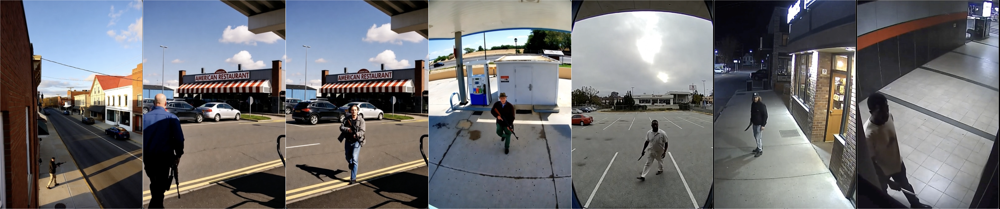

In [3]:
util.plot_image_grid(image_arr_list, 1, len(image_arr_list), return_fig=True, border=1, border_color="white", color_format="BGR")

# Visual Anonymization Inference

### Initial Config

In [4]:
detection_classes = [0] # person
detector_imgsz = None

## AN System: YOLO8 Seg + SAHI

In [5]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__yolo",
                    detector_version="yolov8m-seg__sahi",
                    detector_imgsz=detector_imgsz,
                    detection_thr=0.25,
                    detection_classes=detection_classes
                    )

init_anonymizer...
{'detector_name': 'body__yolo', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolov8m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_height': 640, 'slice_width': 640, 'overlap_height_ratio': 0.2, 'overlap_width_ratio': 0.2}, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolov8m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_height': 640, 'slice_width': 640, 'overlap_height_ratio': 0.2, 'overlap_width_ratio': 0.2}, 'device': 'cuda'}
model:  yolov8m-seg
sahi_kwargs:  {'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolov8m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_heig

ANInference.inference: 
Processing ANInference.inference: 
YOLOv8m-seg summary (fused): 105 layers, 27,268,704 parameters, 0 gradients, 104.5 GFLOPs
YOLOv8m-seg summary (fused): 105 layers, 27,268,704 parameters, 0 gradients, 104.5 GFLOPs
YOLOv8m-seg summary (fused): 105 layers, 27,268,704 parameters, 0 gradients, 104.5 GFLOPs
YOLOv8m-seg summary (fused): 105 layers, 27,268,704 parameters, 0 gradients, 104.5 GFLOPs
multiprocessor failed: 'Conv' object has no attribute 'bn'. rollbacking to single processor.


100%|██████████| 7/7 [00:03<00:00,  2.06it/s]


ANInference.inference is done!
process time: 8.3415 seconds.


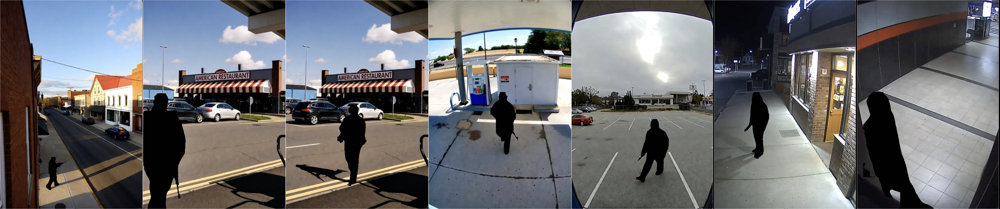

In [6]:
success, image_arr_anonymized_list = ANObj.inference(image_arr_list)
if success:
    util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="BGR")

## AN System: YOLO11 Seg + SAHI

In [7]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__yolo",
                    detector_version="yolo11m-seg__sahi",
                    detector_imgsz=detector_imgsz,
                    detection_thr=0.25,
                    detection_classes=detection_classes
                    )

init_anonymizer...
{'detector_name': 'body__yolo', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolo11m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_height': 640, 'slice_width': 640, 'overlap_height_ratio': 0.2, 'overlap_width_ratio': 0.2}, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolo11m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_height': 640, 'slice_width': 640, 'overlap_height_ratio': 0.2, 'overlap_width_ratio': 0.2}, 'device': 'cuda'}
model:  yolo11m-seg
sahi_kwargs:  {'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolo11m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_heig

ANInference.inference: 
Processing ANInference.inference: 
YOLO11m-seg summary (fused): 138 layers, 22,396,992 parameters, 0 gradients, 113.2 GFLOPs
YOLO11m-seg summary (fused): 138 layers, 22,396,992 parameters, 0 gradients, 113.2 GFLOPs
YOLO11m-seg summary (fused): 138 layers, 22,396,992 parameters, 0 gradients, 113.2 GFLOPs
ANInference.inference is done!
process time: 5.2819 seconds.


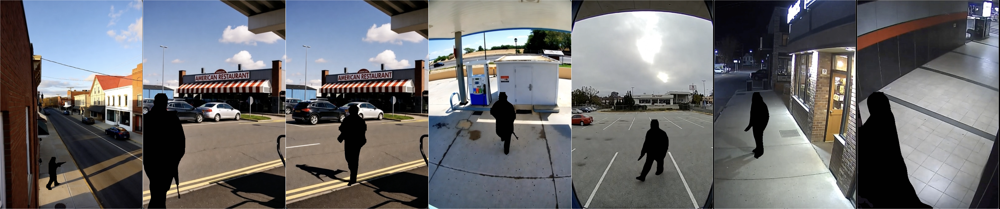

In [8]:
success, image_arr_anonymized_list = ANObj.inference(image_arr_list)
if success:
    util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="BGR")

## AN System: YOLO26 Seg + SAHI

In [9]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__yolo",
                    detector_version="yolo26m-seg__sahi",
                    detector_imgsz=detector_imgsz,
                    detection_thr=0.25,
                    detection_classes=detection_classes
                    )

init_anonymizer...
{'detector_name': 'body__yolo', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolo26m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_height': 640, 'slice_width': 640, 'overlap_height_ratio': 0.2, 'overlap_width_ratio': 0.2}, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolo26m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_height': 640, 'slice_width': 640, 'overlap_height_ratio': 0.2, 'overlap_width_ratio': 0.2}, 'device': 'cuda'}
model:  yolo26m-seg
sahi_kwargs:  {'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'yolo26m-seg', 'detection_thr': 0.25, 'imgsz': None, 'sahi_kwargs': {'slice_heig

ANInference.inference: 
Processing ANInference.inference: 
YOLO26m-seg summary (fused): 149 layers, 23,569,148 parameters, 0 gradients, 121.5 GFLOPs
YOLO26m-seg summary (fused): 149 layers, 23,569,148 parameters, 0 gradients, 121.5 GFLOPs
YOLO26m-seg summary (fused): 149 layers, 23,569,148 parameters, 0 gradients, 121.5 GFLOPs
ANInference.inference is done!
process time: 5.4987 seconds.


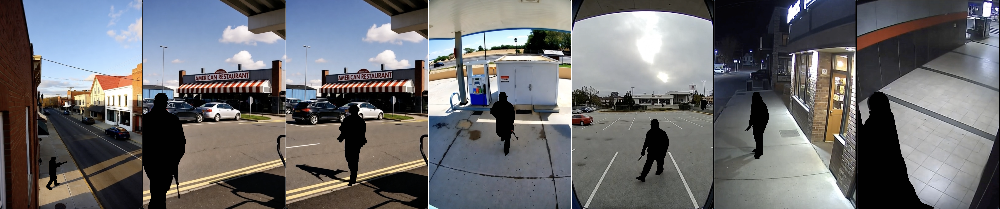

In [10]:
success, image_arr_anonymized_list = ANObj.inference(image_arr_list)
if success:
    util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="BGR")

## AN System: RF-DETR Seg

In [11]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__rfdetr",
                    detector_version="RFDETRSegMedium",
                    detector_imgsz=detector_imgsz,
                    detection_thr=0.35,
                    detection_classes=detection_classes
                    )

init_anonymizer...
{'detector_name': 'body__rfdetr', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'RFDETRSegMedium', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'RFDETRSegMedium', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}
model:  RFDETRSegMedium
loading RFDETRSegMedium
[2026-10-23 18:29:03] [INFO] rf-detr - File /home/mulugetawa/.roboflow/models/rf-detr-seg-medium.pt already exists with correct MD5 hash.


[2026-10-23 18:29:03] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-23 18:29:03] [WARNING] rf-detr - Using patch size 12 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-23 18:29:04] [INFO] rf-detr - File /home/mulugetawa/.roboflow/models/rf-detr-seg-medium.pt already exists with correct MD5 hash.


[2026-10-23 18:29:04] [WARNING] rf-detr - load_pretrain_weights: checkpoint lacks args.num_queries / args.group_detr; falling back to flat slice. With group_detr=13 this may scramble per-group query structure if the checkpoint was trained with group_detr > 1.
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.
[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!


{'method': <function ConventionalImageAnonymizer.silhoutte at 0x7f35672e94e0>, 'kwargs': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}}


ANInference.inference: 
Processing ANInference.inference: 
ANInference.inference is done!
process time: 2.0911 seconds.


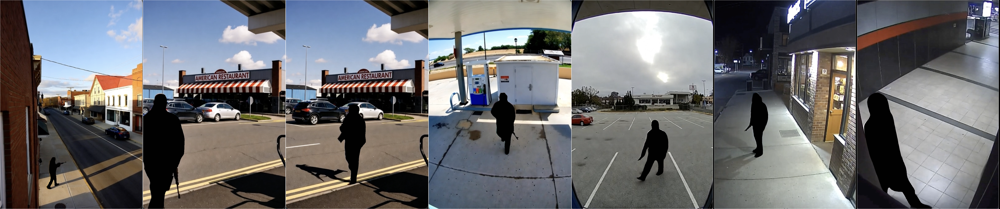

In [12]:
success, image_arr_anonymized_list = ANObj.inference(image_arr_list)
if success:
    util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="BGR")

## AN System (Our GDSN): Grounding DINO + SAM2 (Large) + Negative Seg (Ours)

In [13]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__grounddino_sam",
                    detector_version="grounding-dino-tiny__sam2.1-hiera-large",
                    detector_imgsz=detector_imgsz,
                    detection_thr=0.35,
                    detection_classes=detection_classes
                    )

init_anonymizer...
{'detector_name': 'body__grounddino_sam', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-large', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-large', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}
model:  grounding-dino-tiny__sam2.1-hiera-large
loading grounding-dino-tiny, and sam2.1-hiera-large


Loading weights: 100%|██████████| 978/978 [00:01<00:00, 524.50it/s] 
[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 741/741 [00:01<00:00, 377.94it/s]

{'method': <function ConventionalImageAnonymizer.silhoutte at 0x7f35672e94e0>, 'kwargs': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}}


ANInference.inference: 
Processing ANInference.inference: 
ANInference.inference is done!
process time: 7.6219 seconds.


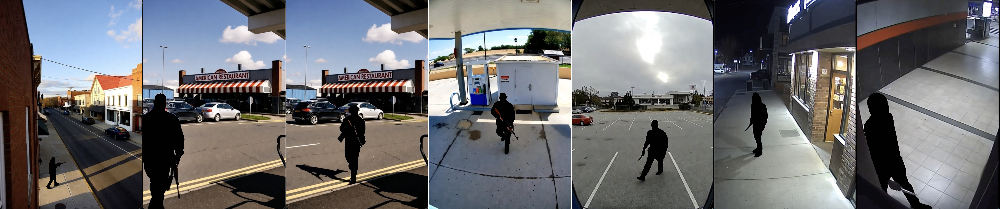

In [14]:
success, image_arr_anonymized_list = ANObj.inference(image_arr_list)
if success:
    util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="BGR")

## AN System (Our GDSN): Grounding DINO + SAM2 (Small) + Negative Seg

In [15]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__grounddino_sam",
                    detector_version="grounding-dino-tiny__sam2.1-hiera-small",
                    detector_imgsz=detector_imgsz,
                    detection_thr=0.35,
                    detection_classes=detection_classes
                    )

init_anonymizer...
{'detector_name': 'body__grounddino_sam', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-small', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-small', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}
model:  grounding-dino-tiny__sam2.1-hiera-small
loading grounding-dino-tiny, and sam2.1-hiera-small


Loading weights: 100%|██████████| 978/978 [00:00<00:00, 4304.10it/s]
[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 357/357 [00:00<00:00, 513.17it/s]


{'method': <function ConventionalImageAnonymizer.silhoutte at 0x7f35672e94e0>, 'kwargs': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}}


ANInference.inference: 
Processing ANInference.inference: 
ANInference.inference is done!
process time: 6.0455 seconds.


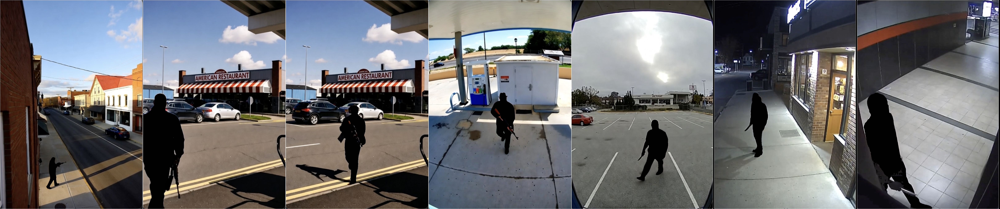

In [16]:
success, image_arr_anonymized_list = ANObj.inference(image_arr_list)
if success:
    util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="BGR")

## AN System (Our GDSN): Grounding DINO + SAM2 (Tiny) + Negative Seg (Ours)

In [17]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__grounddino_sam",
                    detector_version="grounding-dino-tiny__sam2.1-hiera-tiny",
                    detector_imgsz=detector_imgsz,
                    detection_thr=0.35,
                    detection_classes=detection_classes
                    )

init_anonymizer...
{'detector_name': 'body__grounddino_sam', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-tiny', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-tiny', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}
model:  grounding-dino-tiny__sam2.1-hiera-tiny
loading grounding-dino-tiny, and sam2.1-hiera-tiny


Loading weights: 100%|██████████| 978/978 [00:00<00:00, 4975.93it/s]
[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 309/309 [00:00<00:00, 564.21it/s]

{'method': <function ConventionalImageAnonymizer.silhoutte at 0x7f35672e94e0>, 'kwargs': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}}


ANInference.inference: 
Processing ANInference.inference: 
ANInference.inference is done!
process time: 5.7115 seconds.


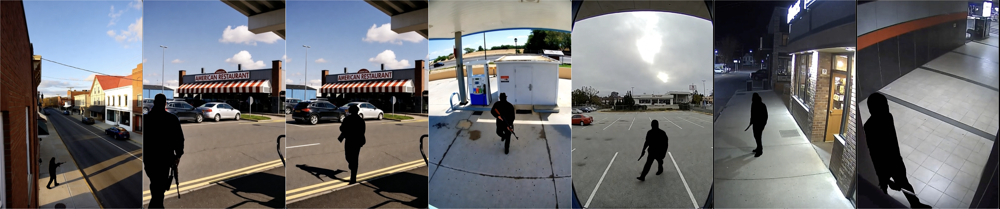

In [18]:
success, image_arr_anonymized_list = ANObj.inference(image_arr_list)
if success:
    util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="BGR")